# Лабораторная работа 2. Идентификация выбросов: метод ближайшего соседа и ODIN

> Сгенерируйте обучающую выборку для решения задачи распознавания растровых изображений,
> содержащую выбросы типа 0. Назовём выбросы этого типа выбросами типа 1, если они не
> распознаются как выбросы с помощью метода ближайшего соседа, выбросами типа 2 — выбросы
> типа 0, которые не распознаются с помощью метода ODIN. Реализуйте оба подхода к
> идентификации выбросов. Сравните результаты их работы.

## 1. Настройка окружения

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20260926
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 2. Эталоны и зашумление

Эталоны — цифры $8 \times 8$, нарисованные вручную (`#` — чёрный пиксель), сглаженные средним по
окрестности $3 \times 3$ и растянутые на $[0, 255]$, как в лабораторной работе 1. Зашумление
равномерное (п. 3.5): $a_{ij} = \mathrm{clip}(a^{(p)}_{ij} + \varepsilon_{ij}, 0, 255)$,
$\varepsilon_{ij} \sim \mathsf U[-\delta, \delta]$, $\delta = \ell \cdot 255$.

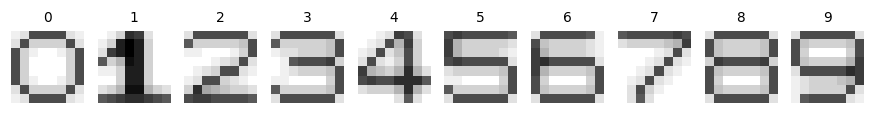

In [2]:
DIGIT_ART = {
    0: ["..####..", ".#....#.", "#......#", "#......#", "#......#", "#......#", ".#....#.", "..####.."],
    1: ["...##...", "..###...", ".####...", "#..##...", "...##...", "...##...", "...##...", "########"],
    2: [".######.", "#......#", ".......#", "......#.", "....##..", "..##....", ".#......", "########"],
    3: [".######.", "#......#", ".......#", "..#####.", ".......#", ".......#", "#......#", ".######."],
    4: ["....##..", "...#.#..", "..#..#..", ".#...#..", "#....#..", "########", ".....#..", ".....#.."],
    5: ["########", "#.......", "#.......", "#######.", ".......#", ".......#", "#......#", ".######."],
    6: [".######.", "#.......", "#.......", "#######.", "#......#", "#......#", "#......#", ".######."],
    7: ["########", ".......#", "......#.", ".....#..", "....#...", "...#....", "..#.....", "..#....."],
    8: [".######.", "#......#", "#......#", ".######.", "#......#", "#......#", "#......#", ".######."],
    9: [".######.", "#......#", "#......#", "#......#", ".#######", ".......#", "......#.", ".#####.."],
}

N_CLASSES = len(DIGIT_ART)
BIN = np.array([[[ch == "#" for ch in row] for row in DIGIT_ART[c]] for c in DIGIT_ART], dtype=float)
_pad = np.pad(BIN, ((0, 0), (1, 1), (1, 1)))
_box = sum(_pad[:, i:i + 8, j:j + 8] for i in range(3) for j in range(3)) / 9   # среднее по 3x3
_mix = (BIN + _box) / 2
PROTO = _mix / _mix.max() * 255                                     # эталоны (10, 8, 8)

fig, axes = plt.subplots(1, N_CLASSES, figsize=(10, 1.4))
for c, ax in enumerate(axes):
    ax.imshow(PROTO[c], cmap="gray_r", vmin=0, vmax=255)
    ax.set_title(c, fontsize=9)
    ax.axis("off")
plt.show()

def add_noise(images, level, rng):
    eps = rng.uniform(-1, 1, images.shape) * level * 255
    return np.clip(images + eps, 0, 255)

def distances(X):
    """Евклидовы расстояния между всеми парами; на диагонали inf — элемент не сосед сам себе."""
    D = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))
    np.fill_diagonal(D, np.inf)
    return D

def neighbours(D, k):
    """Индексы k ближайших соседей каждого элемента."""
    return np.argsort(D, axis=1, kind="stable")[:, :k]

## 3. Выборка с выбросами типа 0

**Выбросы типа 0** — элементы, которые мы сами внесли в выборку, поэтому их список известен. Два
вида: `noisy` — сильно зашумлённое изображение с правильной
меткой, `mislabel` — обычное изображение с меткой другой цифры.

По 20 изображений каждой цифры с шумом $\ell = 0{,}2$, плюс 10 выбросов `noisy` ($\ell_{\text{out}} = 1$)
и 10 `mislabel`: всего 220 элементов. При $\ell = 0{,}2$ чистая выборка сама не содержит выбросов
(проверка ниже).

In [3]:
def make_sample(rng, n_per_class=20, n_noisy=10, n_mislabel=10, level=0.2, level_out=1.0):
    """Возвращает X (n, 64), y (n,) и kind (n,): 'clean' | 'noisy' | 'mislabel'."""
    y_clean = np.repeat(np.arange(N_CLASSES), n_per_class)
    y_noisy = rng.integers(0, N_CLASSES, n_noisy)
    c_mis = rng.integers(0, N_CLASSES, n_mislabel)                          # настоящая цифра
    y_mis = (c_mis + rng.integers(1, N_CLASSES, n_mislabel)) % N_CLASSES    # заведомо чужая метка

    X = np.concatenate([add_noise(PROTO[y_clean], level, rng),
                        add_noise(PROTO[y_noisy], level_out, rng),
                        add_noise(PROTO[c_mis], level, rng)]).reshape(-1, 64)
    y = np.concatenate([y_clean, y_noisy, y_mis])
    kind = np.array(["clean"] * len(y_clean) + ["noisy"] * n_noisy + ["mislabel"] * n_mislabel)
    return X, y, kind

rng = np.random.default_rng(SEED)
X, y, kind = make_sample(rng)
print(pd.Series(kind).value_counts().to_string())

clean       200
noisy        10
mislabel     10


## 4. Методы идентификации выбросов

* **Метод ближайшего соседа.** Выброс — элемент выборки, который неверно классифицируется методом
  ближайшего соседа по выборке, из которой он сам исключён.
* **ODIN.** Строится kNN-граф: дуга $i \to j$, если $x^{(j)}$ — один из $k$ ближайших соседей
  $x^{(i)}$. Элемент — выброс, если степень его вершины меньше порога $T$. В ориентированном графе
  степень — число входящих дуг (indegree), в неориентированном — число всех смежных вершин.

In [4]:
def detect_nn(X, y, D=None):
    """Метод ближайшего соседа: выброс, если метка ближайшего соседа не совпадает со своей."""
    D = distances(X) if D is None else D
    return y[neighbours(D, 1)[:, 0]] != y

def degree(X, k, directed=True, D=None):
    """Степени вершин kNN-графа."""
    D = distances(X) if D is None else D
    nb = neighbours(D, k)
    n = len(X)
    A = np.zeros((n, n), dtype=bool)        # A[i, j] = True: дуга i -> j
    A[np.repeat(np.arange(n), k), nb.ravel()] = True
    if directed:
        return A.sum(axis=0)                # число входящих дуг
    return (A | A.T).sum(axis=1)            # число смежных вершин

def detect_odin(X, k, T, directed=True, D=None):
    """ODIN: выброс, если степень вершины меньше порога T."""
    return degree(X, k, directed, D) < T

## 5. Сравнение на одной выборке

Параметры ODIN: ориентированный граф, $k = 15$, $T = 2$ (выбор — в разделе 6).

In [5]:
K, T = 15, 2
D = distances(X)
found_nn = detect_nn(X, y, D)
found_odin = detect_odin(X, K, T, D=D)
is_out = kind != "clean"

table = pd.DataFrame({
    "всего": pd.Series(kind).value_counts(),
    "найдено NN": pd.Series(kind[found_nn]).value_counts(),
    "найдено ODIN": pd.Series(kind[found_odin]).value_counts(),
}).fillna(0).astype(int)
print(table)          # строка clean — ложные срабатывания

type1 = is_out & ~found_nn
type2 = is_out & ~found_odin
print("\nВыбросы типа 1:", dict(pd.Series(kind[type1]).value_counts()))
print("Выбросы типа 2:", dict(pd.Series(kind[type2]).value_counts()))
print("Не найдены ни одним методом:", (type1 & type2).sum())

false_nn = found_nn & ~is_out
print("\nЛожных срабатываний NN:", false_nn.sum(),
      "| mislabel:", (kind[neighbours(D, 1)[false_nn, 0]] == "mislabel").sum(),
      "| noisy:", (kind[neighbours(D, 1)[false_nn, 0]] == "noisy").sum())

false_odin = found_odin & ~is_out
print("\nЛожных срабатываний ODIN:", false_odin.sum(),
      "| mislabel:", (kind[neighbours(D, 1)[false_odin, 0]] == "mislabel").sum(),
      "| noisy:", (kind[neighbours(D, 1)[false_odin, 0]] == "noisy").sum())

          всего  найдено NN  найдено ODIN
clean       200          11             0
mislabel     10          10             0
noisy        10           2            10

Выбросы типа 1: {'noisy': np.int64(8)}
Выбросы типа 2: {'mislabel': np.int64(10)}
Не найдены ни одним методом: 0

Ложных срабатываний NN: 11 | mislabel: 11 | noisy: 0

Ложных срабатываний ODIN: 0 | mislabel: 0 | noisy: 0


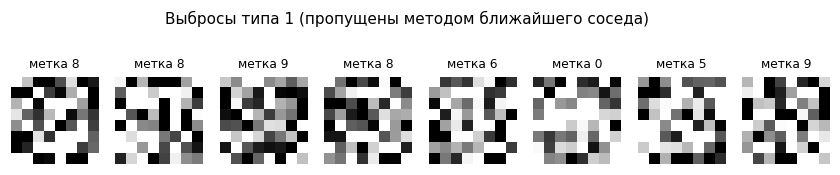

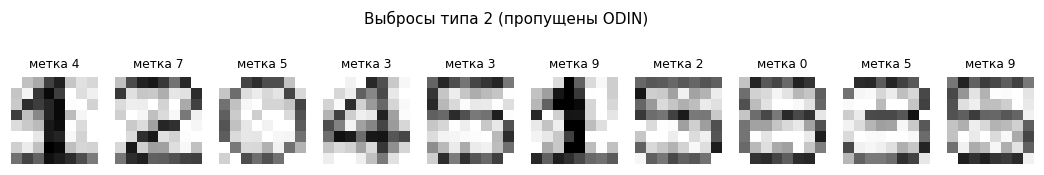

In [6]:
def show(idx, title):
    fig, axes = plt.subplots(1, max(len(idx), 1), figsize=(1.2 * max(len(idx), 1), 1.8), squeeze=False)
    for ax, i in zip(axes[0], idx):
        ax.imshow(X[i].reshape(8, 8), cmap="gray_r", vmin=0, vmax=255)
        ax.set_title(f"метка {y[i]}", fontsize=8)
    for ax in axes[0]:
        ax.axis("off")
    fig.suptitle(title, fontsize=10, y=1.05)
    plt.show()

show(np.flatnonzero(type1), "Выбросы типа 1 (пропущены методом ближайшего соседа)")
show(np.flatnonzero(type2), "Выбросы типа 2 (пропущены ODIN)")

## 6. Параметры ODIN

Для каждой пары $(k, T)$ — среднее по 20 выборкам число найденных выбросов каждого вида и число
ложных срабатываний (чистых элементов, объявленных выбросами).

In [7]:
samples = [make_sample(np.random.default_rng(SEED + r)) for r in range(20)]

rows = []
for Xr, yr, kr in samples:
    Dr = distances(Xr)
    for directed in [True, False]:
        for k in [3, 5, 10, 15]:
            deg = degree(Xr, k, directed, Dr)
            # в неориентированном графе степень всегда >= k, поэтому порог сдвинут на k
            for T in [1, 2, 3]:
                found = deg < (T if directed else k + T)
                rows.append({"граф": "ориент." if directed else "неориент.", "k": k, "T": T,
                             "noisy (из 10)": found[kr == "noisy"].sum(),
                             "mislabel (из 10)": found[kr == "mislabel"].sum(),
                             "ложные (из 200)": found[kr == "clean"].sum()})
print(pd.DataFrame(rows).groupby(["граф", "k", "T"]).mean().round(1))

                noisy (из 10)  mislabel (из 10)  ложные (из 200)
граф      k  T                                                  
неориент. 3  1           10.0               3.6             78.5
             2           10.0               5.9            130.7
             3           10.0               7.6            161.4
          5  1           10.0               2.9             61.4
             2           10.0               5.0            110.3
             3           10.0               6.9            141.6
          10 1            9.8               1.8             38.6
             2           10.0               4.0             79.6
             3           10.0               5.8            114.9
          15 1            9.8               1.4             26.4
             2           10.0               3.0             67.4
             3           10.0               5.0            109.4
ориент.   3  1           10.0               0.8             18.6
             2           

Для неориентированного графа в таблице порог указан как $T$, а фактически применяется $k + T$:
у каждой вершины уже есть $k$ собственных дуг.

## 7. Зависимость от силы шума выбросов `noisy`

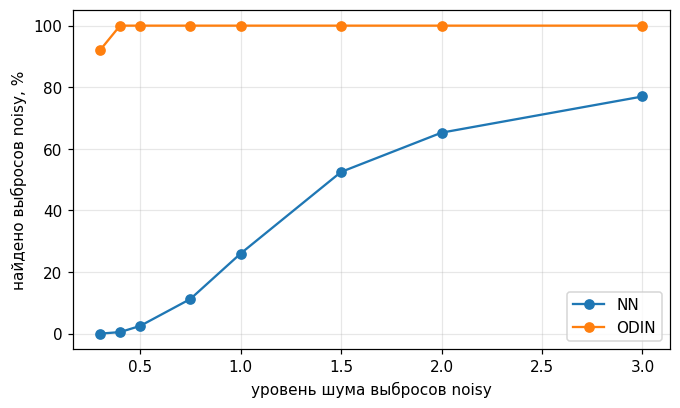

             NN   ODIN
level_out             
0.30        0.0   92.0
0.40        0.5  100.0
0.50        2.5  100.0
0.75       11.2  100.0
1.00       26.0  100.0
1.50       52.5  100.0
2.00       65.2  100.0
3.00       77.0  100.0


In [8]:
levels = [0.3, 0.4, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
rows = []
for lvl in levels:
    for r in range(20):
        Xr, yr, kr = make_sample(np.random.default_rng(SEED + r), n_noisy=20, n_mislabel=0, level_out=lvl)
        Dr = distances(Xr)
        rows.append({"level_out": lvl,
                     "NN": detect_nn(Xr, yr, Dr)[kr == "noisy"].mean() * 100,
                     "ODIN": detect_odin(Xr, K, T, D=Dr)[kr == "noisy"].mean() * 100})
strength = pd.DataFrame(rows).groupby("level_out").mean()

strength.plot(marker="o", figsize=(7, 4))
plt.xlabel("уровень шума выбросов noisy")
plt.ylabel("найдено выбросов noisy, %")
plt.show()
print(strength.round(1))

## 8. Выводы

* **Методы находят разные выбросы.** Метод ближайшего соседа нашёл все 10 выбросов `mislabel` и
  только 2 из 10 `noisy`. ODIN ($k = 15$, $T = 2$) нашёл все 10 `noisy` и ни одного `mislabel`.
* **Выбросы типа 1** — зашумлённые изображения с правильной меткой (8 из 10), **выбросы типа 2** —
  все ошибки в метке (10 из 10). Пропущенных обоими методами нет: методы дополняют друг друга.
* **Почему так.** Метод ближайшего соседа сравнивает метки, поэтому зашумлённое изображение с верной
  меткой находит, только если шум приблизил его к другой цифре. ODIN ищет элементы, которые никто не
  выбирает в соседи, а `mislabel` лежит среди изображений своей настоящей цифры и выбирается часто.
* **Ложные срабатывания метода ближайшего соседа.** Он объявил выбросами 11 чистых элементов, и у всех
  11 ближайший сосед — выброс `mislabel`: неверная метка «переходит» на соседей.
* **Параметры ODIN.** Ориентированный граф намного лучше: у неориентированного при тех же $k$ и $T$
  26–161 ложное срабатывание из 200. С ростом $k$ ложных срабатываний меньше: при $k = 15$ их нет,
  при $k = 3$, $T = 1$ — 18,6.
* **Сила шума.** ODIN находит 92 % выбросов `noisy` уже при $\ell_{\text{out}} = 0{,}3$ (чистая выборка —
  $\ell = 0{,}2$) и 100 % начиная с 0,4. Метод ближайшего соседа при $\ell_{\text{out}} = 0{,}5$ находит
  2,5 %, а даже при $\ell_{\text{out}} = 3$ — лишь 77 %.